Random image path: Data\food-101\images\waffles\3773199.jpg
Image class: waffles
Height: 512
Width: 512


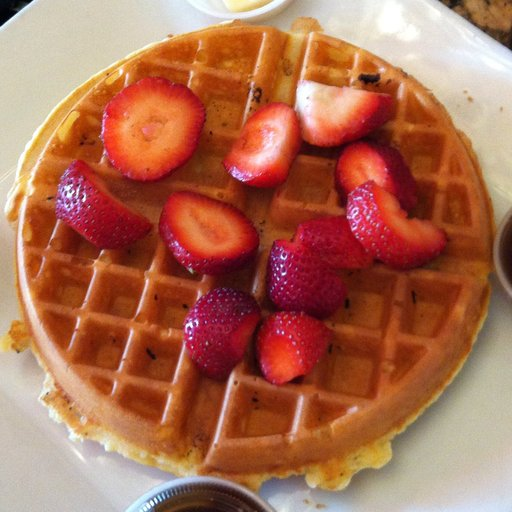

In [2]:
import random
from PIL import Image
from pathlib import Path

image_path = Path("Data/food-101/images")

image_path_list = list(image_path.glob("*/*.jpg"))

random_image_path = random.choice(image_path_list)

image_class = random_image_path.parent.stem

img = Image.open(random_image_path)

print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Height: {img.height}")
print(f"Width: {img.width}")
img

In [3]:
import torch
from torch.utils.data import DataLoader
from torchvision import transforms, datasets

data_transform  = transforms.Compose([
    transforms.Resize(size = (256,256)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

data_transform(img).shape

torch.Size([3, 256, 256])

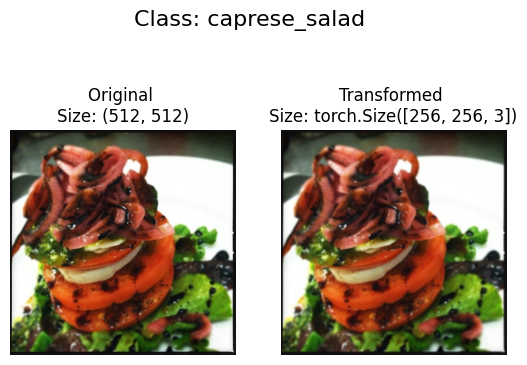

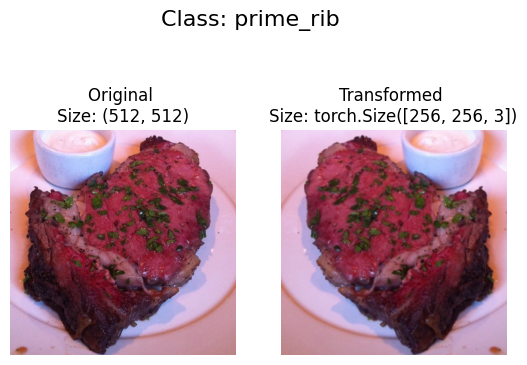

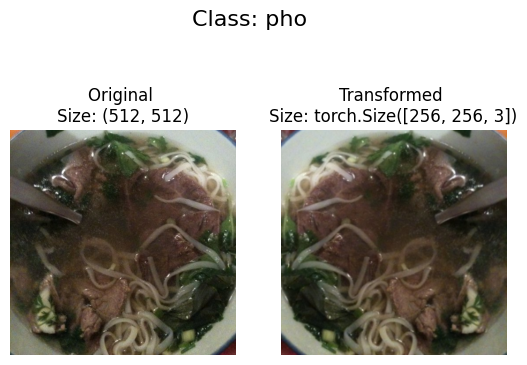

In [4]:
import matplotlib.pyplot as plt
def plot_transformed_images(image_paths: list, transform, n=3):
  # select random images from a path of images and load/transforms them then plots the original vs the transformed version

  random_image_paths = random.sample(image_paths, k=n)
  for image_path in random_image_paths:
    with Image.open(image_path) as f:
      fig, ax = plt.subplots(nrows=1,ncols=2)
      ax[0].imshow(f)
      ax[0].set_title(f"Original \nSize: {f.size}")
      ax[0].axis("off")

      # transform and plot the image
      transformed_image = transform(f).permute(1,2,0) # color channels should be at the last for matplotlib to work
      ax[1].imshow(transformed_image)
      ax[1].set_title(f"Transformed \nSize: {transformed_image.shape}")
      ax[1].axis("off")

      fig.suptitle(f"Class: {image_path.parent.stem}", fontsize=16)

plot_transformed_images(image_path_list, data_transform)

In [32]:
import pandas as pd

train_list_file = "Data/food-101/meta/train.txt"
test_list_file = "Data/food-101/meta/test.txt"

train_df = pd.read_csv(
    train_list_file,
    header = None
)
test_df = pd.read_csv(
    test_list_file,
    header = None
)

train_img_paths = train_df[0].tolist()
test_img_paths = test_df[0].tolist()

train_img_paths, test_img_paths


(['apple_pie/1005649',
  'apple_pie/1014775',
  'apple_pie/1026328',
  'apple_pie/1028787',
  'apple_pie/1043283',
  'apple_pie/1050519',
  'apple_pie/1057749',
  'apple_pie/1057810',
  'apple_pie/1072416',
  'apple_pie/1074856',
  'apple_pie/1074942',
  'apple_pie/1076891',
  'apple_pie/1077610',
  'apple_pie/1077964',
  'apple_pie/1088809',
  'apple_pie/1097378',
  'apple_pie/1103795',
  'apple_pie/1109597',
  'apple_pie/1111062',
  'apple_pie/1112300',
  'apple_pie/1112838',
  'apple_pie/1121884',
  'apple_pie/112378',
  'apple_pie/1133267',
  'apple_pie/1142597',
  'apple_pie/1147371',
  'apple_pie/1154371',
  'apple_pie/1158360',
  'apple_pie/1159801',
  'apple_pie/1165004',
  'apple_pie/1166116',
  'apple_pie/1166210',
  'apple_pie/116697',
  'apple_pie/1174241',
  'apple_pie/1174949',
  'apple_pie/1177254',
  'apple_pie/118237',
  'apple_pie/1184568',
  'apple_pie/1185445',
  'apple_pie/1185654',
  'apple_pie/1191665',
  'apple_pie/1196628',
  'apple_pie/1199851',
  'apple_pie/1

In [33]:
train_img_paths = ["Data/food-101/images/" + item + ".jpg" for item in train_img_paths]
test_img_paths = ["Data/food-101/images/" + item + ".jpg" for item in test_img_paths]
train_img_paths, test_img_paths

(['Data/food-101/images/apple_pie/1005649.jpg',
  'Data/food-101/images/apple_pie/1014775.jpg',
  'Data/food-101/images/apple_pie/1026328.jpg',
  'Data/food-101/images/apple_pie/1028787.jpg',
  'Data/food-101/images/apple_pie/1043283.jpg',
  'Data/food-101/images/apple_pie/1050519.jpg',
  'Data/food-101/images/apple_pie/1057749.jpg',
  'Data/food-101/images/apple_pie/1057810.jpg',
  'Data/food-101/images/apple_pie/1072416.jpg',
  'Data/food-101/images/apple_pie/1074856.jpg',
  'Data/food-101/images/apple_pie/1074942.jpg',
  'Data/food-101/images/apple_pie/1076891.jpg',
  'Data/food-101/images/apple_pie/1077610.jpg',
  'Data/food-101/images/apple_pie/1077964.jpg',
  'Data/food-101/images/apple_pie/1088809.jpg',
  'Data/food-101/images/apple_pie/1097378.jpg',
  'Data/food-101/images/apple_pie/1103795.jpg',
  'Data/food-101/images/apple_pie/1109597.jpg',
  'Data/food-101/images/apple_pie/1111062.jpg',
  'Data/food-101/images/apple_pie/1112300.jpg',
  'Data/food-101/images/apple_pie/111283

In [34]:
import shutil
from tqdm.auto import tqdm
import os

#shutil.move('Data/food-101/images/apple_pie/1112300.jpg', 'Data/test')

def move_files(base_dest, src):

    print(f"Moving files to {base_dest}....")


    for img in tqdm(src):

        class_name = os.path.basename(os.path.dirname(img))
        dest = os.path.join(base_dest, class_name)
        os.makedirs(dest, exist_ok=True)

        try:
            # 2. Move the file
            shutil.move(img, dest)
        
        except FileNotFoundError:
            # This skips files that are already moved or were never found
            print(f"\nWarning: {img} not found. Skipping.")
        
        except shutil.Error as e:
            # This catches other errors, e.g., permissions
            print(f"\nError moving {img}: {e}")
            
    print(f"Finished moving files.")
    
train_dest = "Data/train"
test_dest = "Data/test"

move_files(train_dest, train_img_paths)
move_files(test_dest, test_img_paths)

Moving files to Data/train....


100%|██████████| 75750/75750 [03:12<00:00, 393.45it/s]


Finished moving files.
Moving files to Data/test....


100%|██████████| 25250/25250 [01:25<00:00, 296.77it/s]

Finished moving files.
